# Exploring the Validated Synthetic Temporal Benchmark

This notebook is an interactive guide to the shared longitudinal dataset and its Food Allergy (FA) and GI/stomach-upset outcomes. It reads the validated 1,000-patient artifacts without modifying or regenerating them. It does **not** train TemporalTree.

> **Important:** The benchmark contains both model-visible data and private ground-truth artifacts. Private ground-truth information is for validation and interpretation only and must never be passed to TemporalTree training.

## 1. Imports

In [1]:
import hashlib
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## 2. Path configuration

Edit this cell if the repository or artifact locations change. The small root check lets the notebook run when the kernel starts in either the repository root or `notebooks/`.

In [24]:
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "data" / "temporal_benchmark").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "temporal_benchmark_v2"
X_PATH = DATA_DIR / "temporal_benchmark_5000.pkl"
FA_LABELS_PATH = DATA_DIR / "temporal_benchmark_fa_labels_5000.pkl"
FA_GROUND_TRUTH_PATH = DATA_DIR / "temporal_benchmark_ground_truth_5000.pkl"
FA_METADATA_PATH = DATA_DIR / "temporal_benchmark_metadata_5000.json"
GI_LABELS_PATH = DATA_DIR / "temporal_benchmark_gi_labels_5000.pkl"
GI_GROUND_TRUTH_PATH = DATA_DIR / "temporal_benchmark_gi_ground_truth_5000.pkl"
GI_METADATA_PATH = DATA_DIR / "temporal_benchmark_gi_metadata_5000.json"

ARTIFACT_PATHS = [
    X_PATH, FA_LABELS_PATH, FA_GROUND_TRUTH_PATH, FA_METADATA_PATH,
    GI_LABELS_PATH, GI_GROUND_TRUTH_PATH, GI_METADATA_PATH,
]
missing_files = [path for path in ARTIFACT_PATHS if not path.is_file()]
assert not missing_files, f"Missing benchmark artifacts: {missing_files}"
display(pd.DataFrame({"artifact": [p.name for p in ARTIFACT_PATHS], "path": [str(p) for p in ARTIFACT_PATHS]}))

,artifact,path
0,temporal_benchmark_5000.pkl,/mnt/drive1/home/noreena/TemporalDecisionTree_...
1,temporal_benchmark_fa_labels_5000.pkl,/mnt/drive1/home/noreena/TemporalDecisionTree_...
2,temporal_benchmark_ground_truth_5000.pkl,/mnt/drive1/home/noreena/TemporalDecisionTree_...
3,temporal_benchmark_metadata_5000.json,/mnt/drive1/home/noreena/TemporalDecisionTree_...
4,temporal_benchmark_gi_labels_5000.pkl,/mnt/drive1/home/noreena/TemporalDecisionTree_...
5,temporal_benchmark_gi_ground_truth_5000.pkl,/mnt/drive1/home/noreena/TemporalDecisionTree_...
6,temporal_benchmark_gi_metadata_5000.json,/mnt/drive1/home/noreena/TemporalDecisionTree_...


## 3. Load all files

Each artifact is loaded separately so its role and schema remain visible. No artifact is merged into X or written back to disk.

In [25]:
# A. Shared longitudinal X — MODEL-VISIBLE DATA
longitudinal_x = pd.read_pickle(X_PATH)

In [4]:
# B. Food Allergy targets — MODEL TARGETS
fa_labels = pd.read_pickle(FA_LABELS_PATH)

In [5]:
# C. Food Allergy validation data — PRIVATE GROUND TRUTH
fa_ground_truth = pd.read_pickle(FA_GROUND_TRUTH_PATH)

In [6]:
# D. Food Allergy benchmark metadata
with FA_METADATA_PATH.open(encoding="utf-8") as file:
    fa_metadata = json.load(file)

In [7]:
# E. GI/stomach-upset targets — MODEL TARGETS
gi_labels = pd.read_pickle(GI_LABELS_PATH)

In [8]:
# F. GI/stomach-upset validation data — PRIVATE GROUND TRUTH
gi_ground_truth = pd.read_pickle(GI_GROUND_TRUTH_PATH)

In [9]:
# G. GI/stomach-upset benchmark metadata
with GI_METADATA_PATH.open(encoding="utf-8") as file:
    gi_metadata = json.load(file)

## 4. Dataset Files and Their Roles

| Role | Artifact | Appropriate use |
|---|---|---|
| **MODEL-VISIBLE DATA** | `temporal_benchmark_1000.pkl` | Longitudinal predictors and anchors supplied to a model |
| **MODEL TARGET** | `temporal_benchmark_fa_labels_1000.pkl` | FA outcome labels |
| **MODEL TARGET** | `temporal_benchmark_gi_labels_1000.pkl` | GI outcome labels |
| **PRIVATE GROUND TRUTH** | `temporal_benchmark_ground_truth_1000.pkl` | Latent feeding trajectory, transitions, FA OR/coefficient/probability |
| **PRIVATE GROUND TRUTH** | `temporal_benchmark_gi_ground_truth_1000.pkl` | True-window GI predictors and GI probability |
| Documentation/audit | FA and GI metadata JSON files | Configuration, scientific constants, and validation results |

**Never pass either private ground-truth dataframe to model training.** Doing so would leak the answers and invalidate the benchmark.

In [35]:
# longitudinal_x.head(20)
# longitudinal_x[longitudinal_x['patient_id'] == 'TB_00015'].head(30)
longitudinal_x[(longitudinal_x['patient_id'] == 'TB_00099') & (longitudinal_x['feature_name'] == 'LengthCm')]

,patient_id,time,feature_name,value
30295,TB_00099,2019-02-01,LengthCm,49.7
30321,TB_00099,2019-03-02,LengthCm,52.9
30345,TB_00099,2019-04-03,LengthCm,56.4
30380,TB_00099,2019-06-02,LengthCm,61.7
30408,TB_00099,2019-07-31,LengthCm,66.3
30449,TB_00099,2019-11-02,LengthCm,69.8
30485,TB_00099,2020-01-31,LengthCm,72.9
30556,TB_00099,2020-08-02,LengthCm,77.7


In [36]:
longitudinal_x.head(20)

,patient_id,time,feature_name,value
0,TB_00000,2019-07-06,ApgarFiveMinutes,10.0
1,TB_00000,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00
2,TB_00000,2019-07-06,BirthOrder,4.0
3,TB_00000,2019-07-06,BirthWeightKg,3.45
4,TB_00000,2019-07-06,BreastMilkYN,1.0
5,TB_00000,2019-07-06,FormulaYN,1.0
6,TB_00000,2019-07-06,GestationalAgeWeeks,38.2
7,TB_00000,2019-07-06,LengthCm,48.2
8,TB_00000,2019-07-06,MaternalAgeYears,30.0
9,TB_00000,2019-07-06,SocioEconomicScore,-0.443


In [27]:
longitudinal_x['feature_name'].unique()

array(['ApgarFiveMinutes', 'Birth Date Anchor', 'BirthOrder',
       'BirthWeightKg', 'BreastMilkYN', 'FormulaYN',
       'GestationalAgeWeeks', 'LengthCm', 'MaternalAgeYears',
       'SocioEconomicScore', 'WeightKg', 'ClinicalVisitYN', 'DiarrheaYN',
       'FoodExposureYN', 'GISymptomYN', 'VomitingYN', 'NOW Anchor'],
      dtype=object)

Total unique patients: 5,000
Every patient has exactly one Birth Date Anchor: PASS
Every patient has exactly one NOW Anchor: PASS

Patient-level age dataframe:
feature_name patient_id birth_date   now_date  age_days  age_months  age_years
0              TB_00000 2019-07-06 2021-05-13       677   22.240473   1.853525
1              TB_00001 2020-01-07 2021-10-04       636   20.893561   1.741273
2              TB_00002 2019-03-23 2020-10-29       586   19.250986   1.604381
3              TB_00003 2019-05-07 2021-03-20       683   22.437582   1.869952
4              TB_00004 2020-10-12 2022-06-14       610   20.039422   1.670089

Descriptive statistics for age at NOW in approximate months:
count    5000.000000
mean       20.988883
std         1.740698
min        17.936925
25%        19.480946
50%        20.959264
75%        22.503285
max        24.014455
Name: age_months, dtype: float64

Number of unique ages:
Unique ages in days: 186
Unique approximate ages in months: 186

Age-group defi

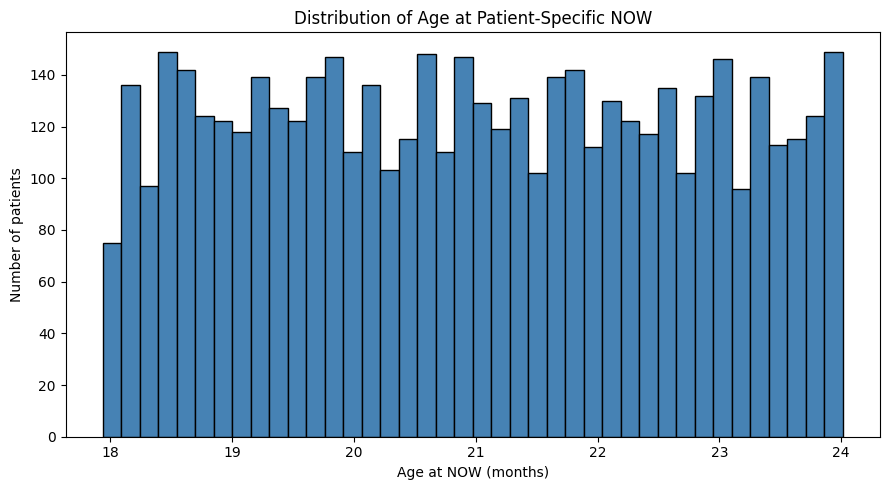

In [28]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd


# Load the model-visible longitudinal dataset

data = longitudinal_x

# Extract the two anchor types
anchor_names = ["Birth Date Anchor", "NOW Anchor"]
anchor_rows = data.loc[
    data["feature_name"].isin(anchor_names),
    ["patient_id", "feature_name", "value"],
].copy()

# Verify that every patient has exactly one of each anchor
anchor_counts = (
    anchor_rows.groupby(["patient_id", "feature_name"])
    .size()
    .unstack(fill_value=0)
    .reindex(columns=anchor_names, fill_value=0)
)

total_patients = data["patient_id"].nunique()

assert total_patients == 5000, (
    f"Expected 5,000 patients, found {total_patients}."
)
assert anchor_counts["Birth Date Anchor"].eq(1).all(), (
    "Not every patient has exactly one Birth Date Anchor."
)
assert anchor_counts["NOW Anchor"].eq(1).all(), (
    "Not every patient has exactly one NOW Anchor."
)

print(f"Total unique patients: {total_patients:,}")
print("Every patient has exactly one Birth Date Anchor: PASS")
print("Every patient has exactly one NOW Anchor: PASS")

# Convert the long-format anchors into one row per patient
age_data = (
    anchor_rows.pivot(
        index="patient_id",
        columns="feature_name",
        values="value",
    )
    .rename(
        columns={
            "Birth Date Anchor": "birth_date",
            "NOW Anchor": "now_date",
        }
    )
    .reset_index()
)

# Ensure both anchor values are valid timestamps
age_data["birth_date"] = pd.to_datetime(
    age_data["birth_date"], errors="coerce"
)
age_data["now_date"] = pd.to_datetime(
    age_data["now_date"], errors="coerce"
)

assert age_data["birth_date"].notna().all(), (
    "At least one Birth Date Anchor is not a valid timestamp."
)
assert age_data["now_date"].notna().all(), (
    "At least one NOW Anchor is not a valid timestamp."
)

# Calculate age at NOW
age_data["age_days"] = (
    age_data["now_date"] - age_data["birth_date"]
).dt.days

# Approximate conversions:
# 1 month = 30.44 days
# 1 year = 365.25 days
age_data["age_months"] = age_data["age_days"] / 30.44
age_data["age_years"] = age_data["age_days"] / 365.25

print("\nPatient-level age dataframe:")
print(age_data.head())

print("\nDescriptive statistics for age at NOW in approximate months:")
print(age_data["age_months"].describe())

print("\nNumber of unique ages:")
print(f"Unique ages in days: {age_data['age_days'].nunique()}")
print(
    "Unique approximate ages in months: "
    f"{age_data['age_months'].nunique()}"
)

# Non-overlapping intervals:
# [18, 19), [19, 20), ..., [23, 24)
#
# Because calendar-month ages converted using days / 30.44 can fall slightly
# below 18 or at/above 24, edge categories are included to cover everyone.
age_bins = [
    float("-inf"),
    18,
    19,
    20,
    21,
    22,
    23,
    24,
    float("inf"),
]

age_labels = [
    "<18 months",
    "18–<19 months",
    "19–<20 months",
    "20–<21 months",
    "21–<22 months",
    "22–<23 months",
    "23–<24 months",
    "≥24 months",
]

age_data["age_group"] = pd.cut(
    age_data["age_months"],
    bins=age_bins,
    labels=age_labels,
    right=False,
)

age_group_summary = (
    age_data["age_group"]
    .value_counts(sort=False)
    .rename("patient_count")
    .to_frame()
)

age_group_summary["percentage"] = (
    100 * age_group_summary["patient_count"] / len(age_data)
)

print("\nAge-group definitions use [lower, upper) intervals:")
print(age_group_summary)

assert age_group_summary["patient_count"].sum() == 5000

# Histogram of age at NOW
plt.figure(figsize=(9, 5))
plt.hist(
    age_data["age_months"],
    bins=40,
    color="steelblue",
    edgecolor="black",
)
plt.title("Distribution of Age at Patient-Specific NOW")
plt.xlabel("Age at NOW (months)")
plt.ylabel("Number of patients")
plt.tight_layout()
plt.show()

In [10]:
def display_dataframe_overview(name, dataframe):
    """Display the same compact structural audit for a loaded dataframe."""
    print(f"{name}: shape={dataframe.shape}")
    print(f"Columns: {dataframe.columns.tolist()}")
    display(dataframe.dtypes.rename("dtype").to_frame())
    display(dataframe.head())
    if "patient_id" in dataframe:
        print(f"Unique patients: {dataframe['patient_id'].nunique():,}")
    display(dataframe.isna().sum().rename("missing_values").to_frame())

display_dataframe_overview("Shared longitudinal X [MODEL-VISIBLE]", longitudinal_x)

Shared longitudinal X [MODEL-VISIBLE]: shape=(1803917, 4)
Columns: ['patient_id', 'time', 'feature_name', 'value']


,dtype
patient_id,object
time,datetime64[ns]
feature_name,object
value,object


,patient_id,time,feature_name,value
0,TB_00000,2019-07-06,ApgarFiveMinutes,10.0
1,TB_00000,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00
2,TB_00000,2019-07-06,BirthOrder,4.0
3,TB_00000,2019-07-06,BirthWeightKg,3.45
4,TB_00000,2019-07-06,BreastMilkYN,1.0


Unique patients: 5,000


,missing_values
patient_id,0
time,0
feature_name,0
value,18546


In [11]:
display_dataframe_overview("FA labels [MODEL TARGET]", fa_labels)
display_dataframe_overview("FA ground truth [PRIVATE]", fa_ground_truth)

FA labels [MODEL TARGET]: shape=(1000, 2)
Columns: ['patient_id', 'label']


,dtype
patient_id,object
label,int64


,patient_id,label
0,TB_00000,0
1,TB_00001,0
2,TB_00002,0
3,TB_00003,0
4,TB_00004,0


Unique patients: 1,000


,missing_values
patient_id,0
label,0


FA ground truth [PRIVATE]: shape=(1000, 13)
Columns: ['patient_id', 'birth_date', 'now', 'now_age_months', 'feeding_group', 'feeding_template', 'conceptual_states', 'initial_state', 'transition_times', 'transition_states', 'feeding_or', 'beta_j', 'fa_probability']


,dtype
patient_id,object
birth_date,datetime64[ns]
now,datetime64[ns]
now_age_months,int64
feeding_group,object
feeding_template,object
conceptual_states,object
initial_state,object
transition_times,object
transition_states,object


,patient_id,birth_date,now,now_age_months,feeding_group,feeding_template,conceptual_states,initial_state,transition_times,transition_states,feeding_or,beta_j,fa_probability
0,TB_00000,2019-07-06,2021-03-06,20,2.2,"M,M,F,F","(M, M, F, F)",M,"(2019-08-06 00:00:00,)","(F,)",0.49,-0.713350,0.040388
1,TB_00001,2020-01-07,2021-09-07,20,3,"B,B,B,B","(B, B, B, B)",B,(),(),2.95,1.081805,0.202160
2,TB_00002,2019-03-23,2021-02-23,23,2.0,"F,F,F,F","(F, F, F, F)",F,(),(),1.00,0.000000,0.079099
3,TB_00003,2019-05-07,2021-03-07,22,2.3,"M,M,M,F","(M, M, M, F)",M,"(2019-08-24 00:00:00,)","(F,)",0.54,-0.616186,0.044326
4,TB_00004,2020-10-12,2022-09-12,23,3,"B,B,B,B","(B, B, B, B)",B,(),(),2.95,1.081805,0.202160


Unique patients: 1,000


,missing_values
patient_id,0
birth_date,0
now,0
now_age_months,0
feeding_group,0
feeding_template,0
conceptual_states,0
initial_state,0
transition_times,0
transition_states,0


In [12]:
display_dataframe_overview("GI labels [MODEL TARGET]", gi_labels)
display_dataframe_overview("GI ground truth [PRIVATE]", gi_ground_truth)

GI labels [MODEL TARGET]: shape=(1000, 2)
Columns: ['patient_id', 'label']


,dtype
feature_name,
patient_id,object
label,int64


feature_name,patient_id,label
0,TB_00000,0
1,TB_00001,0
2,TB_00002,0
3,TB_00003,0
4,TB_00004,0


Unique patients: 1,000


,missing_values
feature_name,
patient_id,0
label,0


GI ground truth [PRIVATE]: shape=(1000, 7)
Columns: ['patient_id', 'V_i', 'D_i', 'G_i', 'n_active_predictors', 'gi_probability', 'gi_label']


,dtype
feature_name,
patient_id,object
V_i,int64
D_i,int64
G_i,int64
n_active_predictors,int64
gi_probability,float64
gi_label,int64


feature_name,patient_id,V_i,D_i,G_i,n_active_predictors,gi_probability,gi_label
0,TB_00000,0,1,0,1,0.142646,0
1,TB_00001,0,0,0,0,0.062399,0
2,TB_00002,0,0,1,1,0.117468,0
3,TB_00003,0,0,1,1,0.117468,0
4,TB_00004,0,0,0,0,0.062399,0


Unique patients: 1,000


,missing_values
feature_name,
patient_id,0
V_i,0
D_i,0
G_i,0
n_active_predictors,0
gi_probability,0
gi_label,0


In [13]:
print("FA metadata top-level keys:")
display(list(fa_metadata.keys()))
display({
    "benchmark_version": fa_metadata["benchmark_version"],
    "cohort_size": fa_metadata["cohort_size"],
    "longitudinal_schema": fa_metadata["longitudinal_schema"],
    "label_schema": fa_metadata["label_schema"],
    "feature_count": len(fa_metadata["feature_names"]),
    "all_validation_checks_passed": all(fa_metadata["validation"]["checks"].values()),
})
print("GI metadata top-level keys:")
display(list(gi_metadata.keys()))
display({
    "benchmark_version": gi_metadata["benchmark_version"],
    "cohort_size": gi_metadata["cohort_size"],
    "true_temporal_window": gi_metadata["true_temporal_window"],
    "excluded_distractors": gi_metadata["excluded_model_visible_distractors"],
    "all_validation_checks_passed": all(gi_metadata["validation"]["checks"].values()),
})

FA metadata top-level keys:


['benchmark_version',
 'cohort_size',
 'distractors',
 'fa',
 'feature_names',
 'feeding',
 'gi_label_status',
 'ground_truth_windows',
 'label_schema',
 'longitudinal_schema',
 'master_seed',
 'missingness',
 'now_age_distribution',
 'output_directory',
 'rng_streams',
 'validation']

{'benchmark_version': 'phase_1_fa_v1',
 'cohort_size': 1000,
 'longitudinal_schema': ['patient_id', 'time', 'feature_name', 'value'],
 'label_schema': ['patient_id', 'label'],
 'feature_count': 17,
 'all_validation_checks_passed': True}

GI metadata top-level keys:


['active_predictor_distribution',
 'benchmark_version',
 'calibrated_intercept',
 'cohort_size',
 'excluded_model_visible_distractors',
 'external_ground_truth_inputs',
 'independence_audit',
 'label_schema',
 'master_seed',
 'mean_theoretical_probability',
 'outcome_interpretation',
 'positive_count',
 'predictor_distribution',
 'predictors',
 'private_ground_truth_schema',
 'probability_by_active_predictor_count',
 'probability_distribution',
 'realized_prevalence',
 'rng',
 'source_artifacts',
 'source_x_status',
 'target_prevalence',
 'temporal_specificity_audit',
 'true_temporal_window',
 'validation']

{'benchmark_version': 'phase_2_gi_v1',
 'cohort_size': 1000,
 'true_temporal_window': {'anchor': 'NOW Anchor',
  'bounds': 'inclusive',
  'end_offset': '0 months',
  'start_offset': '-1 calendar month'},
 'excluded_distractors': ['FoodExposureYN', 'ClinicalVisitYN'],
 'all_validation_checks_passed': True}

## 5. Exploring the Shared Longitudinal Dataset

X uses one row per patient, timestamp, and feature observation: `patient_id`, `time`, `feature_name`, `value`. Repeated measurements therefore appear on separate rows. Anchor values are timestamps stored in the mixed-type `value` column; ordinary feature values are numeric.

In [14]:
feature_counts = longitudinal_x["feature_name"].value_counts().sort_index()
rows_per_patient = longitudinal_x.groupby("patient_id").size()
display(pd.Series({
    "patients": longitudinal_x["patient_id"].nunique(),
    "rows": len(longitudinal_x),
    "unique_features": longitudinal_x["feature_name"].nunique(),
    "earliest_time": longitudinal_x["time"].min(),
    "latest_time": longitudinal_x["time"].max(),
}, name="value"))
print("Feature names:")
display(sorted(longitudinal_x["feature_name"].unique()))
display(feature_counts.rename("rows").to_frame())
display(rows_per_patient.describe().rename("rows_per_patient").to_frame())

patients                          1000
rows                            362001
unique_features                     17
earliest_time      2018-01-01 00:00:00
latest_time        2022-12-19 00:00:00
Name: value, dtype: object

Feature names:


['ApgarFiveMinutes',
 'Birth Date Anchor',
 'BirthOrder',
 'BirthWeightKg',
 'BreastMilkYN',
 'ClinicalVisitYN',
 'DiarrheaYN',
 'FoodExposureYN',
 'FormulaYN',
 'GISymptomYN',
 'GestationalAgeWeeks',
 'LengthCm',
 'MaternalAgeYears',
 'NOW Anchor',
 'SocioEconomicScore',
 'VomitingYN',
 'WeightKg']

,rows
ApgarFiveMinutes,1000
Birth Date Anchor,1000
BirthOrder,1000
BirthWeightKg,1000
BreastMilkYN,25806
ClinicalVisitYN,45781
DiarrheaYN,45781
FoodExposureYN,45781
FormulaYN,25806
GISymptomYN,45781


,rows_per_patient
count,1000.000000
mean,362.001000
std,33.449991
min,307.000000
25%,329.000000
50%,364.000000
75%,392.000000
max,420.000000


In [15]:
anchor_names = ["Birth Date Anchor", "NOW Anchor"]
anchor_rows = longitudinal_x[longitudinal_x["feature_name"].isin(anchor_names)].copy()
anchor_rows["valid_timestamp"] = pd.to_datetime(anchor_rows["value"], errors="coerce").notna()
anchor_audit = anchor_rows.groupby("feature_name").agg(
    rows=("patient_id", "size"),
    patients=("patient_id", "nunique"),
    valid_timestamps=("valid_timestamp", "sum"),
).reindex(anchor_names)
display(anchor_audit)
assert anchor_audit["patients"].eq(longitudinal_x["patient_id"].nunique()).all()
assert anchor_audit["valid_timestamps"].eq(anchor_audit["rows"]).all()

,rows,patients,valid_timestamps
feature_name,,,
Birth Date Anchor,1000,1000,1000
NOW Anchor,1000,1000,1000


## 6. Inspect One Patient

Change only `PATIENT_ID` and rerun this section. The default is selected from X, so it is always valid. GI-related rows include the three true GI feature types plus the two model-visible distractors.

In [16]:
PATIENT_ID = longitudinal_x["patient_id"].iloc[0]  # e.g. "TB_00000"
assert PATIENT_ID in set(longitudinal_x["patient_id"]), "Unknown PATIENT_ID"
patient_rows = longitudinal_x[longitudinal_x["patient_id"].eq(PATIENT_ID)].sort_values(
    ["time", "feature_name"]
).copy()
display(patient_rows)

,patient_id,time,feature_name,value
0,TB_00000,2019-07-06,ApgarFiveMinutes,7.0
1,TB_00000,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00
2,TB_00000,2019-07-06,BirthOrder,3.0
3,TB_00000,2019-07-06,BirthWeightKg,3.05
4,TB_00000,2019-07-06,BreastMilkYN,1.0
...,...,...,...,...
345,TB_00000,2021-03-06,DiarrheaYN,1.0
346,TB_00000,2021-03-06,FoodExposureYN,0.0
347,TB_00000,2021-03-06,GISymptomYN,0.0
348,TB_00000,2021-03-06,NOW Anchor,2021-03-06 00:00:00


In [17]:
feeding_features = ["FormulaYN", "BreastMilkYN"]
gi_related_features = ["VomitingYN", "DiarrheaYN", "GISymptomYN", "FoodExposureYN", "ClinicalVisitYN"]
patient_anchor_rows = patient_rows[patient_rows["feature_name"].str.endswith("Anchor")]
patient_feeding_rows = patient_rows[patient_rows["feature_name"].isin(feeding_features)]
patient_gi_rows = patient_rows[patient_rows["feature_name"].isin(gi_related_features)]
patient_other_rows = patient_rows[~patient_rows["feature_name"].isin(feeding_features + gi_related_features) & ~patient_rows["feature_name"].str.endswith("Anchor")]

print("Anchors"); display(patient_anchor_rows)
print("Feeding"); display(patient_feeding_rows)
print("GI-related features"); display(patient_gi_rows)
print("Other features"); display(patient_other_rows)

Anchors


,patient_id,time,feature_name,value
1,TB_00000,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00
348,TB_00000,2021-03-06,NOW Anchor,2021-03-06 00:00:00


Feeding


,patient_id,time,feature_name,value
4,TB_00000,2019-07-06,BreastMilkYN,1.0
5,TB_00000,2019-07-06,FormulaYN,1.0
9,TB_00000,2019-07-11,BreastMilkYN,1.0
10,TB_00000,2019-07-11,FormulaYN,1.0
16,TB_00000,2019-07-16,BreastMilkYN,1.0
17,TB_00000,2019-07-16,FormulaYN,1.0
18,TB_00000,2019-07-24,BreastMilkYN,1.0
19,TB_00000,2019-07-24,FormulaYN,1.0
25,TB_00000,2019-07-27,BreastMilkYN,1.0
26,TB_00000,2019-07-27,FormulaYN,1.0


GI-related features


,patient_id,time,feature_name,value
11,TB_00000,2019-07-15,ClinicalVisitYN,1.0
12,TB_00000,2019-07-15,DiarrheaYN,0.0
13,TB_00000,2019-07-15,FoodExposureYN,0.0
14,TB_00000,2019-07-15,GISymptomYN,0.0
15,TB_00000,2019-07-15,VomitingYN,0.0
...,...,...,...,...
344,TB_00000,2021-03-06,ClinicalVisitYN,1.0
345,TB_00000,2021-03-06,DiarrheaYN,1.0
346,TB_00000,2021-03-06,FoodExposureYN,0.0
347,TB_00000,2021-03-06,GISymptomYN,0.0


Other features


,patient_id,time,feature_name,value
0,TB_00000,2019-07-06,ApgarFiveMinutes,7.0
2,TB_00000,2019-07-06,BirthOrder,3.0
3,TB_00000,2019-07-06,BirthWeightKg,3.05
6,TB_00000,2019-07-06,GestationalAgeWeeks,38.8
7,TB_00000,2019-07-06,MaternalAgeYears,42.0
8,TB_00000,2019-07-06,SocioEconomicScore,-1.118
33,TB_00000,2019-08-05,LengthCm,50.7
34,TB_00000,2019-08-05,WeightKg,3.67
57,TB_00000,2019-09-07,LengthCm,58.0
59,TB_00000,2019-09-07,WeightKg,4.36


## 7. Patient Timeline Relative to Anchors

Calendar-month offsets in the benchmark use calendar arithmetic. The tables below also provide approximate elapsed days and months to make the timeline easy to scan.

In [18]:
selected_anchors = patient_anchor_rows.set_index("feature_name")["value"]
birth_date = pd.Timestamp(selected_anchors["Birth Date Anchor"])
now = pd.Timestamp(selected_anchors["NOW Anchor"])
age_at_now_days = (now - birth_date).days
print(f"Birth Date: {birth_date.date()}")
print(f"NOW: {now.date()}")
print(f"Age at NOW: {age_at_now_days} days (approximately {age_at_now_days / 30.4375:.2f} months)")

patient_timeline = patient_rows.copy()
patient_timeline["days_from_birth"] = (patient_timeline["time"] - birth_date).dt.days
patient_timeline["approx_months_from_birth"] = patient_timeline["days_from_birth"] / 30.4375
patient_timeline["days_from_now"] = (patient_timeline["time"] - now).dt.days
patient_timeline["approx_months_from_now"] = patient_timeline["days_from_now"] / 30.4375
display(patient_timeline[["time", "feature_name", "value", "days_from_birth", "approx_months_from_birth", "days_from_now", "approx_months_from_now"]])

Birth Date: 2019-07-06
NOW: 2021-03-06
Age at NOW: 609 days (approximately 20.01 months)


,time,feature_name,value,days_from_birth,approx_months_from_birth,days_from_now,approx_months_from_now
0,2019-07-06,ApgarFiveMinutes,7.0,0,0.000000,-609,-20.008214
1,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00,0,0.000000,-609,-20.008214
2,2019-07-06,BirthOrder,3.0,0,0.000000,-609,-20.008214
3,2019-07-06,BirthWeightKg,3.05,0,0.000000,-609,-20.008214
4,2019-07-06,BreastMilkYN,1.0,0,0.000000,-609,-20.008214
...,...,...,...,...,...,...,...
345,2021-03-06,DiarrheaYN,1.0,609,20.008214,0,0.000000
346,2021-03-06,FoodExposureYN,0.0,609,20.008214,0,0.000000
347,2021-03-06,GISymptomYN,0.0,609,20.008214,0,0.000000
348,2021-03-06,NOW Anchor,2021-03-06 00:00:00,609,20.008214,0,0.000000


<ipython-input-1-663ad06b9119>:8: MatplotlibDeprecationWarning: Passing the minor parameter of set_ticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
  ax.set_yticks(range(len(plot_features)), plot_features)


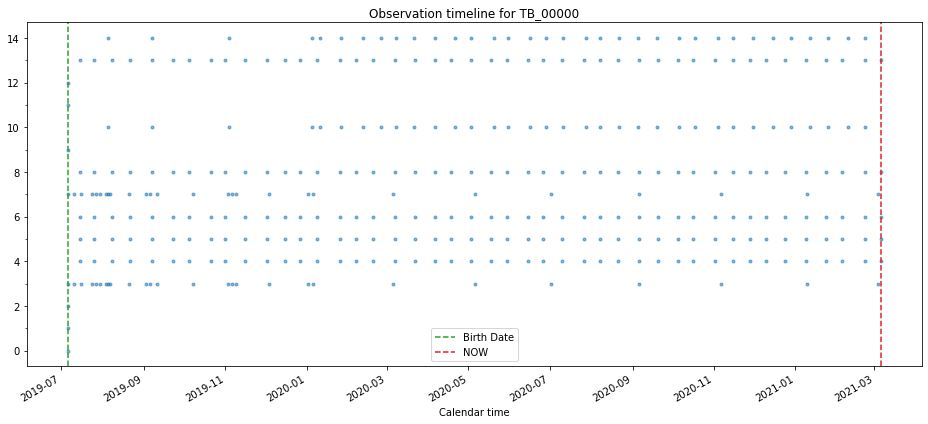

In [19]:
plot_rows = patient_rows[~patient_rows["feature_name"].str.endswith("Anchor")].copy()
plot_features = sorted(plot_rows["feature_name"].unique())
feature_y = {feature: index for index, feature in enumerate(plot_features)}
fig, ax = plt.subplots(figsize=(13, 6))
ax.scatter(plot_rows["time"], plot_rows["feature_name"].map(feature_y), s=9, alpha=0.55)
ax.axvline(birth_date, color="tab:green", linestyle="--", label="Birth Date")
ax.axvline(now, color="tab:red", linestyle="--", label="NOW")
ax.set_yticks(range(len(plot_features)), plot_features)
ax.set_title(f"Observation timeline for {PATIENT_ID}")
ax.set_xlabel("Calendar time")
ax.legend()
fig.autofmt_xdate(); plt.tight_layout(); plt.show()

## 8. FA Feeding Trajectories

The early feeding state is encoded by two model-visible binary observations:

| State | Meaning | FormulaYN | BreastMilkYN |
|---|---|---:|---:|
| F | Formula only | 1 | 0 |
| M | Mixed feeding | 1 | 1 |
| B | Exclusive Breastfeeding | 0 | 1 |

Every patient has exactly one private feeding-group assignment. The group is not model-visible; TemporalTree must infer the pattern from longitudinal `FormulaYN` and `BreastMilkYN`. Group 6 contains approved inconsistent, multi-transition patterns.

In [20]:
group_full_names = {
    "2.0": "Formula only throughout 0–6 months",
    "2.1": "Mixed to formula at 21 days",
    "2.2": "Mixed to formula after 21 days through 2 months",
    "2.3": "Mixed to formula after 2 through 4 months",
    "2.4": "Mixed throughout 0–6 months",
    "3": "Exclusive breastfeeding throughout 0–6 months",
    "4": "Formula to exclusive breastfeeding at 21 days",
    "5.1": "Exclusive breastfeeding to formula after 21 days through 2 months",
    "5.2": "Exclusive breastfeeding to formula after 2 through 4 months",
    "5.3": "Exclusive breastfeeding to formula after 4 through 6 months",
    "6": "Inconsistent feeding with multiple transitions",
}
feeding_meta = fa_metadata["feeding"]
group_order = list(feeding_meta["empirical_counts"].keys())
feeding_group_reference = pd.DataFrame({
    "group_id": group_order,
    "full_name": [group_full_names[group] for group in group_order],
    "empirical_count": [feeding_meta["empirical_counts"][group] for group in group_order],
    "empirical_proportion": [feeding_meta["sampling_probabilities"][group] for group in group_order],
    "FA_OR": [feeding_meta["odds_ratios"][group] for group in group_order],
})
display(feeding_group_reference)

,group_id,full_name,empirical_count,empirical_proportion,FA_OR
0,2.0,Formula only throughout 0–6 months,41120,0.196793,1.00
1,2.1,Mixed to formula at 21 days,19560,0.093610,0.51
2,2.2,Mixed to formula after 21 days through 2 months,25913,0.124015,0.49
3,2.3,Mixed to formula after 2 through 4 months,6659,0.031869,0.54
4,2.4,Mixed throughout 0–6 months,24817,0.118769,0.47
5,3,Exclusive breastfeeding throughout 0–6 months,40682,0.194696,2.95
6,4,Formula to exclusive breastfeeding at 21 days,5427,0.025973,3.10
7,5.1,Exclusive breastfeeding to formula after 21 da...,21444,0.102627,1.13
8,5.2,Exclusive breastfeeding to formula after 2 thr...,10417,0.049854,1.68
9,5.3,Exclusive breastfeeding to formula after 4 thr...,9205,0.044053,1.60


## 9. View Patients by Feeding Group

> **PRIVATE ANALYSIS ONLY — DO NOT USE FOR TRAINING.** Private ground truth is used only to select and interpret examples; the feeding history shown afterward is exactly what the model can see.

In [21]:
FEEDING_GROUP = "5.2"
assert FEEDING_GROUP in set(fa_ground_truth["feeding_group"]), "Unknown FEEDING_GROUP"
group_patients = fa_ground_truth[fa_ground_truth["feeding_group"].eq(FEEDING_GROUP)]
GROUP_PATIENT_ID = group_patients["patient_id"].iloc[0]
print(f"Patients in group {FEEDING_GROUP}: {len(group_patients)}")
print("Example patient IDs:", group_patients["patient_id"].head().tolist())
display(group_patients[group_patients["patient_id"].eq(GROUP_PATIENT_ID)])

group_private_row = group_patients.iloc[0]
group_birth = group_private_row["birth_date"]
group_six_months = group_birth + pd.DateOffset(months=6)
group_visible_feeding = longitudinal_x[
    longitudinal_x["patient_id"].eq(GROUP_PATIENT_ID)
    & longitudinal_x["feature_name"].isin(feeding_features)
    & longitudinal_x["time"].between(group_birth, group_six_months)
].sort_values(["time", "feature_name"])
print("MODEL-VISIBLE feeding observations from birth through 6 months:")
display(group_visible_feeding)

Patients in group 5.2: 48
Example patient IDs: ['TB_00020', 'TB_00028', 'TB_00052', 'TB_00087', 'TB_00088']


,patient_id,birth_date,now,now_age_months,feeding_group,feeding_template,conceptual_states,initial_state,transition_times,transition_states,feeding_or,beta_j,fa_probability
20,TB_00020,2020-01-08,2021-10-08,21,5.2,"B,B,F,F","(B, B, F, F)",B,"(2020-04-28 00:00:00,)","(F,)",1.68,0.518794,0.126104


MODEL-VISIBLE feeding observations from birth through 6 months:


,patient_id,time,feature_name,value
7415,TB_00020,2020-01-10,BreastMilkYN,1.0
7416,TB_00020,2020-01-10,FormulaYN,0.0
7417,TB_00020,2020-01-14,BreastMilkYN,1.0
7418,TB_00020,2020-01-14,FormulaYN,0.0
7424,TB_00020,2020-01-19,BreastMilkYN,1.0
7425,TB_00020,2020-01-19,FormulaYN,0.0
7426,TB_00020,2020-01-28,BreastMilkYN,1.0
7430,TB_00020,2020-01-28,FormulaYN,0.0
7433,TB_00020,2020-01-29,BreastMilkYN,1.0
7434,TB_00020,2020-01-29,FormulaYN,0.0


## 10. Feeding Boundaries

The corrected benchmark includes exact observations at 21 days and 2, 4, and 6 calendar months. “Before 21 days” below is the latest available paired feeding observation strictly before day 21. These observations reveal the existing single trajectory; they do not assign additional groups.

In [22]:
boundary_private = fa_ground_truth.set_index("patient_id").loc[GROUP_PATIENT_ID]
boundary_birth = boundary_private["birth_date"]
feeding_wide = group_visible_feeding.pivot(index="time", columns="feature_name", values="value").sort_index()
feeding_wide["state"] = np.select(
    [(feeding_wide["FormulaYN"] == 1) & (feeding_wide["BreastMilkYN"] == 0),
     (feeding_wide["FormulaYN"] == 1) & (feeding_wide["BreastMilkYN"] == 1),
     (feeding_wide["FormulaYN"] == 0) & (feeding_wide["BreastMilkYN"] == 1)],
    ["F", "M", "B"], default="invalid"
)
day_21 = boundary_birth + pd.Timedelta(days=21)
boundary_times = {
    "before 21 days": feeding_wide.index[feeding_wide.index < day_21].max(),
    "21 days": day_21,
    "2 calendar months": boundary_birth + pd.DateOffset(months=2),
    "4 calendar months": boundary_birth + pd.DateOffset(months=4),
    "6 calendar months": boundary_birth + pd.DateOffset(months=6),
}
selected_boundaries = feeding_wide.loc[list(boundary_times.values())].copy()
selected_boundaries.insert(0, "boundary", list(boundary_times.keys()))
display(selected_boundaries.reset_index())

feature_name,time,boundary,BreastMilkYN,FormulaYN,state
0,2020-01-28,before 21 days,1.0,0.0,B
1,2020-01-29,21 days,1.0,0.0,B
2,2020-03-08,2 calendar months,1.0,0.0,B
3,2020-05-08,4 calendar months,0.0,1.0,F
4,2020-07-08,6 calendar months,0.0,1.0,F


In [23]:
# Compare one representative patient from each group side-by-side.
comparison_rows = []
for group_id in group_order:
    private = fa_ground_truth[fa_ground_truth["feeding_group"].eq(group_id)].iloc[0]
    patient_id = private["patient_id"]
    birth = private["birth_date"]
    visible = longitudinal_x[
        longitudinal_x["patient_id"].eq(patient_id)
        & longitudinal_x["feature_name"].isin(feeding_features)
        & longitudinal_x["time"].le(birth + pd.DateOffset(months=6))
    ].pivot(index="time", columns="feature_name", values="value").sort_index()
    points = [visible.index[visible.index < birth + pd.Timedelta(days=21)].max(),
              birth + pd.Timedelta(days=21), birth + pd.DateOffset(months=2),
              birth + pd.DateOffset(months=4), birth + pd.DateOffset(months=6)]
    states = []
    for timestamp in points:
        formula, breast = visible.loc[timestamp, ["FormulaYN", "BreastMilkYN"]]
        states.append({(1.0, 0.0): "F", (1.0, 1.0): "M", (0.0, 1.0): "B"}[(formula, breast)])
    comparison_rows.append([group_id, patient_id, *states])
boundary_comparison = pd.DataFrame(comparison_rows, columns=["feeding_group", "patient_id", "before_21d", "at_21d", "at_2m", "at_4m", "at_6m"] )
display(boundary_comparison)

,feeding_group,patient_id,before_21d,at_21d,at_2m,at_4m,at_6m
0,2.0,TB_00002,F,F,F,F,F
1,2.1,TB_00009,M,F,F,F,F
2,2.2,TB_00000,M,M,F,F,F
3,2.3,TB_00003,M,M,M,F,F
4,2.4,TB_00005,M,M,M,M,M
5,3,TB_00001,B,B,B,B,B
6,4,TB_00062,F,B,B,B,B
7,5.1,TB_00016,B,B,F,F,F
8,5.2,TB_00020,B,B,B,F,F
9,5.3,TB_00006,B,B,B,B,F


## 11. FA Label Generation Summary

FA depends only on the complete early feeding trajectory in the main benchmark. Experiment 3 odds ratios (ORs) set the relative effects, with coefficient $\beta_j = \ln(OR_j)$. The intercept $\beta_0$ was calibrated over the realized cohort to a mean theoretical prevalence of approximately 10%. Each final binary label was then sampled from its patient-specific probability using a Bernoulli draw.

A **stochastic label** means the probability controls the chance of the outcome, not its certainty: a patient with high probability may receive label 0, and a patient with low probability may receive label 1.

In [24]:
fa_summary = pd.Series({
    "calibrated_beta0": fa_metadata["fa"]["calibrated_intercept"],
    "target_prevalence": fa_metadata["fa"]["target_prevalence"],
    "mean_theoretical_probability": fa_ground_truth["fa_probability"].mean(),
    "realized_prevalence": fa_labels["label"].mean(),
    "FA_positive_count": int(fa_labels["label"].sum()),
    "FA_negative_count": int((fa_labels["label"] == 0).sum()),
})
display(fa_summary.rename("value").to_frame())

,value
calibrated_beta0,-2.454653
target_prevalence,0.100000
mean_theoretical_probability,0.100000
realized_prevalence,0.094000
FA_positive_count,94.000000
FA_negative_count,906.000000


## 12. FA Group-Level Summary

> **PRIVATE ANALYSIS ONLY — DO NOT USE FOR TRAINING.** This table joins target labels to private trajectory information solely for benchmark interpretation.

,n,OR,theoretical_P_FA,FA_positive_count,realized_FA_prevalence
feeding_group,,,,,
2.0,198,1.00,0.079099,13,0.065657
2.1,98,0.51,0.041967,2,0.020408
2.2,110,0.49,0.040388,4,0.036364
2.3,38,0.54,0.044326,0,0.000000
2.4,116,0.47,0.038803,2,0.017241
3,200,2.95,0.202160,44,0.220000
4,29,3.10,0.210278,6,0.206897
5.1,98,1.13,0.088472,6,0.061224
5.2,48,1.68,0.126104,7,0.145833


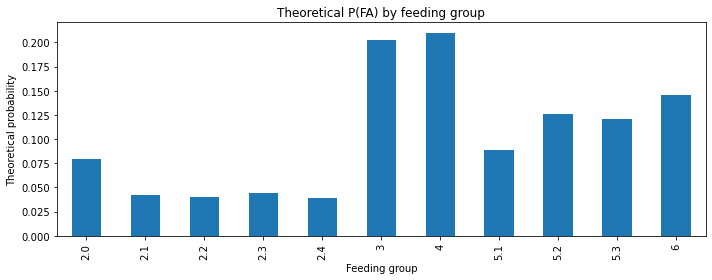

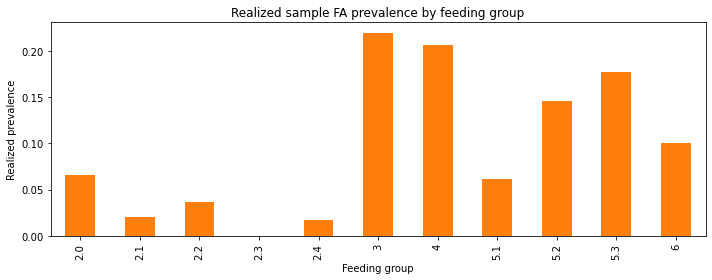

In [25]:
fa_private_analysis = fa_ground_truth.merge(
    fa_labels.rename(columns={"label": "fa_label"}), on="patient_id", validate="one_to_one"
)
fa_group_summary = fa_private_analysis.groupby("feeding_group", sort=False).agg(
    n=("patient_id", "size"),
    OR=("feeding_or", "first"),
    theoretical_P_FA=("fa_probability", "mean"),
    FA_positive_count=("fa_label", "sum"),
    realized_FA_prevalence=("fa_label", "mean"),
).reindex(group_order)
display(fa_group_summary)

ax = fa_group_summary["theoretical_P_FA"].plot.bar(figsize=(10, 4), color="tab:blue")
ax.set(title="Theoretical P(FA) by feeding group", xlabel="Feeding group", ylabel="Theoretical probability")
plt.tight_layout(); plt.show()
ax = fa_group_summary["realized_FA_prevalence"].plot.bar(figsize=(10, 4), color="tab:orange")
ax.set(title="Realized sample FA prevalence by feeding group", xlabel="Feeding group", ylabel="Realized prevalence")
plt.tight_layout(); plt.show()

## 13. Inspect Individual FA Cases

The following positive and negative examples emphasize that theoretical risk and the sampled outcome are different quantities.

In [26]:
FA_POSITIVE_PATIENT_ID = fa_private_analysis.loc[fa_private_analysis["fa_label"].eq(1), "patient_id"].iloc[0]
FA_NEGATIVE_PATIENT_ID = fa_private_analysis.loc[fa_private_analysis["fa_label"].eq(0), "patient_id"].iloc[0]
for case_name, patient_id in {"FA-positive": FA_POSITIVE_PATIENT_ID, "FA-negative": FA_NEGATIVE_PATIENT_ID}.items():
    private = fa_private_analysis[fa_private_analysis["patient_id"].eq(patient_id)].iloc[0]
    early = longitudinal_x[
        longitudinal_x["patient_id"].eq(patient_id)
        & longitudinal_x["feature_name"].isin(feeding_features)
        & longitudinal_x["time"].between(private["birth_date"], private["birth_date"] + pd.DateOffset(months=6))
    ].sort_values(["time", "feature_name"])
    print(f"{case_name}: {patient_id}")
    display(pd.Series({"feeding_group": private["feeding_group"], "theoretical_P_FA": private["fa_probability"], "realized_FA_label": private["fa_label"]}, name="value").to_frame())
    display(early)

FA-positive: TB_00006


,value
feeding_group,5.3
theoretical_P_FA,0.120824
realized_FA_label,1


,patient_id,time,feature_name,value
2228,TB_00006,2019-10-30,BreastMilkYN,1.0
2229,TB_00006,2019-10-30,FormulaYN,0.0
2233,TB_00006,2019-11-05,BreastMilkYN,1.0
2234,TB_00006,2019-11-05,FormulaYN,0.0
2240,TB_00006,2019-11-09,BreastMilkYN,1.0
2241,TB_00006,2019-11-09,FormulaYN,0.0
2242,TB_00006,2019-11-16,BreastMilkYN,1.0
2243,TB_00006,2019-11-16,FormulaYN,0.0
2249,TB_00006,2019-11-20,BreastMilkYN,1.0
2250,TB_00006,2019-11-20,FormulaYN,0.0


FA-negative: TB_00000


,value
feeding_group,2.2
theoretical_P_FA,0.040388
realized_FA_label,0


,patient_id,time,feature_name,value
4,TB_00000,2019-07-06,BreastMilkYN,1.0
5,TB_00000,2019-07-06,FormulaYN,1.0
9,TB_00000,2019-07-11,BreastMilkYN,1.0
10,TB_00000,2019-07-11,FormulaYN,1.0
16,TB_00000,2019-07-16,BreastMilkYN,1.0
17,TB_00000,2019-07-16,FormulaYN,1.0
18,TB_00000,2019-07-24,BreastMilkYN,1.0
19,TB_00000,2019-07-24,FormulaYN,1.0
25,TB_00000,2019-07-27,BreastMilkYN,1.0
26,TB_00000,2019-07-27,FormulaYN,1.0


## 14. GI / Stomach-Upset Ground Truth

The true predictive temporal window is **NOW minus 1 calendar month through NOW**, inclusive. The approved private binary predictors are:

- `V_i`: at least one positive `VomitingYN` event in the final month (OR 3.0)
- `D_i`: at least one positive `DiarrheaYN` event in the final month (OR 2.5)
- `G_i`: at least one positive `GISymptomYN` event in the final month (OR 2.0)

These ORs are **synthetic benchmark effect sizes, not empirical clinical estimates**. The intercept $\alpha_0$ was calibrated to a 12% mean theoretical prevalence, and labels were sampled with Bernoulli draws. `FoodExposureYN` and `ClinicalVisitYN` remain model-visible distractors and do not affect GI probability.

## 15. GI Label Summary

In [27]:
gi_summary = pd.Series({
    "calibrated_alpha0": gi_metadata["calibrated_intercept"],
    "target_prevalence": gi_metadata["target_prevalence"],
    "mean_theoretical_probability": gi_ground_truth["gi_probability"].mean(),
    "realized_prevalence": gi_labels["label"].mean(),
    "GI_positive_count": int(gi_labels["label"].sum()),
    "GI_negative_count": int((gi_labels["label"] == 0).sum()),
})
display(gi_summary.rename("value").to_frame())
for column in ["V_i", "D_i", "G_i", "n_active_predictors"]:
    display(gi_ground_truth[column].value_counts().sort_index().rename("patients").to_frame().rename_axis(column))

,value
calibrated_alpha0,-2.709773
target_prevalence,0.120000
mean_theoretical_probability,0.120000
realized_prevalence,0.119000
GI_positive_count,119.000000
GI_negative_count,881.000000


,patients
V_i,
0,826
1,174


,patients
D_i,
0,784
1,216


,patients
G_i,
0,762
1,238


,patients
n_active_predictors,
0,501
1,378
2,113
3,8


## 16. Inspect One GI Patient

Change only `GI_PATIENT_ID`. The event table includes all observations of the three approved feature types and flags whether each falls inside the true patient-specific window.

In [28]:
GI_PATIENT_ID = gi_ground_truth.loc[gi_ground_truth["n_active_predictors"].gt(0), "patient_id"].iloc[0]
gi_feature_names = ["VomitingYN", "DiarrheaYN", "GISymptomYN"]
gi_patient_anchor = longitudinal_x[
    longitudinal_x["patient_id"].eq(GI_PATIENT_ID) & longitudinal_x["feature_name"].eq("NOW Anchor")
]["value"].iloc[0]
gi_now = pd.Timestamp(gi_patient_anchor)
gi_window_start = gi_now - pd.DateOffset(months=1)
gi_patient_events = longitudinal_x[
    longitudinal_x["patient_id"].eq(GI_PATIENT_ID) & longitudinal_x["feature_name"].isin(gi_feature_names)
].sort_values(["time", "feature_name"]).copy()
gi_patient_events["inside_true_GI_window"] = gi_patient_events["time"].between(gi_window_start, gi_now)
print(f"NOW: {gi_now.date()} | true-window start: {gi_window_start.date()}")
display(gi_patient_events)
print("PRIVATE GI ground truth and realized target:")
display(gi_ground_truth[gi_ground_truth["patient_id"].eq(GI_PATIENT_ID)])

NOW: 2021-03-06 | true-window start: 2021-02-06


,patient_id,time,feature_name,value,inside_true_GI_window
12,TB_00000,2019-07-15,DiarrheaYN,0.0,False
14,TB_00000,2019-07-15,GISymptomYN,0.0,False
15,TB_00000,2019-07-15,VomitingYN,0.0,False
21,TB_00000,2019-07-26,DiarrheaYN,0.0,False
23,TB_00000,2019-07-26,GISymptomYN,0.0,False
...,...,...,...,...,...
338,TB_00000,2021-02-22,GISymptomYN,0.0,True
340,TB_00000,2021-02-22,VomitingYN,0.0,True
345,TB_00000,2021-03-06,DiarrheaYN,1.0,True
347,TB_00000,2021-03-06,GISymptomYN,0.0,True


PRIVATE GI ground truth and realized target:


feature_name,patient_id,V_i,D_i,G_i,n_active_predictors,gi_probability,gi_label
0,TB_00000,0,1,0,1,0.142646,0


## 17. GI Positive vs Negative Examples

In [29]:
GI_POSITIVE_PATIENT_ID = gi_ground_truth.loc[gi_ground_truth["gi_label"].eq(1), "patient_id"].iloc[0]
GI_NEGATIVE_PATIENT_ID = gi_ground_truth.loc[gi_ground_truth["gi_label"].eq(0), "patient_id"].iloc[0]
for case_name, patient_id in {"GI-positive": GI_POSITIVE_PATIENT_ID, "GI-negative": GI_NEGATIVE_PATIENT_ID}.items():
    private = gi_ground_truth[gi_ground_truth["patient_id"].eq(patient_id)].iloc[0]
    patient_now = pd.Timestamp(longitudinal_x[longitudinal_x["patient_id"].eq(patient_id) & longitudinal_x["feature_name"].eq("NOW Anchor")]["value"].iloc[0])
    last_month = longitudinal_x[
        longitudinal_x["patient_id"].eq(patient_id)
        & longitudinal_x["feature_name"].isin(gi_feature_names)
        & longitudinal_x["time"].between(patient_now - pd.DateOffset(months=1), patient_now)
    ].sort_values(["time", "feature_name"])
    print(f"{case_name}: {patient_id}")
    display(private[["V_i", "D_i", "G_i", "n_active_predictors", "gi_probability", "gi_label"]].rename("value").to_frame())
    display(last_month)

GI-positive: TB_00026


,value
feature_name,
V_i,1
D_i,0
G_i,1
n_active_predictors,2
gi_probability,0.285363
gi_label,1


,patient_id,time,feature_name,value
10080,TB_00026,2020-05-31,DiarrheaYN,0.0
10082,TB_00026,2020-05-31,GISymptomYN,0.0
10083,TB_00026,2020-05-31,VomitingYN,1.0
10085,TB_00026,2020-06-12,DiarrheaYN,0.0
10087,TB_00026,2020-06-12,GISymptomYN,1.0
10088,TB_00026,2020-06-12,VomitingYN,0.0


GI-negative: TB_00000


,value
feature_name,
V_i,0
D_i,1
G_i,0
n_active_predictors,1
gi_probability,0.142646
gi_label,0


,patient_id,time,feature_name,value
336,TB_00000,2021-02-22,DiarrheaYN,0.0
338,TB_00000,2021-02-22,GISymptomYN,0.0
340,TB_00000,2021-02-22,VomitingYN,0.0
345,TB_00000,2021-03-06,DiarrheaYN,1.0
347,TB_00000,2021-03-06,GISymptomYN,0.0
349,TB_00000,2021-03-06,VomitingYN,0.0


## 18. Temporal Specificity

The same GI feature types occur in several timeline regions. This audit counts positive events and the proportion of patients with at least one positive event in each region, demonstrating that feature identity alone does not reveal the true one-month window. Regions are made non-overlapping here for clarity.

In [30]:
patient_anchors = fa_ground_truth.set_index("patient_id")[["birth_date", "now"]]
gi_event_audit = longitudinal_x[longitudinal_x["feature_name"].isin(gi_feature_names)].copy()
gi_event_audit["numeric_value"] = pd.to_numeric(gi_event_audit["value"], errors="coerce")
gi_event_audit["birth_date"] = gi_event_audit["patient_id"].map(patient_anchors["birth_date"])
gi_event_audit["now"] = gi_event_audit["patient_id"].map(patient_anchors["now"])
birth_6m = gi_event_audit["birth_date"] + pd.DateOffset(months=6)
now_minus_6m = gi_event_audit["now"] - pd.DateOffset(months=6)
now_minus_1m = gi_event_audit["now"] - pd.DateOffset(months=1)
region_masks = {
    "Birth Date 0–6m": gi_event_audit["time"].between(gi_event_audit["birth_date"], birth_6m),
    "Middle history": (gi_event_audit["time"] > birth_6m) & (gi_event_audit["time"] < now_minus_6m),
    "NOW -6m to -1m": (gi_event_audit["time"] >= now_minus_6m) & (gi_event_audit["time"] < now_minus_1m),
    "NOW -1m to NOW (true)": gi_event_audit["time"].between(now_minus_1m, gi_event_audit["now"]),
}
specificity_rows = []
all_patients = pd.Index(longitudinal_x["patient_id"].unique())
for region, mask in region_masks.items():
    region_data = gi_event_audit[mask]
    for feature in gi_feature_names:
        feature_data = region_data[region_data["feature_name"].eq(feature)]
        positive_by_patient = feature_data.groupby("patient_id")["numeric_value"].sum().reindex(all_patients, fill_value=0)
        specificity_rows.append({"region": region, "feature": feature, "positive_event_count": int(positive_by_patient.sum()), "patients_with_positive_event": int(positive_by_patient.gt(0).sum()), "proportion_with_positive_event": positive_by_patient.gt(0).mean()})
temporal_specificity = pd.DataFrame(specificity_rows)
display(temporal_specificity)

,region,feature,positive_event_count,patients_with_positive_event,proportion_with_positive_event
0,Birth Date 0–6m,VomitingYN,1014,659,0.659
1,Birth Date 0–6m,DiarrheaYN,1219,724,0.724
2,Birth Date 0–6m,GISymptomYN,1558,816,0.816
3,Middle history,VomitingYN,1567,801,0.801
4,Middle history,DiarrheaYN,2001,853,0.853
5,Middle history,GISymptomYN,2320,899,0.899
6,NOW -6m to -1m,VomitingYN,868,616,0.616
7,NOW -6m to -1m,DiarrheaYN,1084,677,0.677
8,NOW -6m to -1m,GISymptomYN,1310,756,0.756
9,NOW -1m to NOW (true),VomitingYN,185,174,0.174


## 19. FA and GI Together

This safe patient-level table contains only identifiers and model targets. It does not merge private ground truth into model-visible X.

In [31]:
outcome_summary = fa_labels.rename(columns={"label": "FA_label"}).merge(
    gi_labels.rename(columns={"label": "GI_label"}), on="patient_id", validate="one_to_one"
)
display(outcome_summary.head())
outcome_counts = pd.Series({
    "FA_prevalence": outcome_summary["FA_label"].mean(),
    "GI_prevalence": outcome_summary["GI_label"].mean(),
    "FA_only": int(((outcome_summary["FA_label"] == 1) & (outcome_summary["GI_label"] == 0)).sum()),
    "GI_only": int(((outcome_summary["FA_label"] == 0) & (outcome_summary["GI_label"] == 1)).sum()),
    "both_positive": int(((outcome_summary["FA_label"] == 1) & (outcome_summary["GI_label"] == 1)).sum()),
    "neither": int(((outcome_summary["FA_label"] == 0) & (outcome_summary["GI_label"] == 0)).sum()),
})
display(outcome_counts.rename("value").to_frame())

,patient_id,FA_label,GI_label
0,TB_00000,0,0
1,TB_00001,0,0
2,TB_00002,0,0
3,TB_00003,0,0
4,TB_00004,0,0


,value
FA_prevalence,0.094
GI_prevalence,0.119
FA_only,80.000
GI_only,105.000
both_positive,14.000
neither,801.000


## 20. Playground

Edit the values below and rerun the cells. Feeding-group filtering uses private ground truth and is therefore for exploration only—not training. Calendar-date filters and relative-window filters operate only on model-visible X.

In [32]:
# Editable values
PATIENT_ID = longitudinal_x["patient_id"].iloc[0]
FEATURE_NAME = "VomitingYN"
FEEDING_GROUP = "5.2"  # PRIVATE filtering only
START_DATE = longitudinal_x["time"].min()
END_DATE = START_DATE + pd.DateOffset(months=1)

print("One patient"); display(longitudinal_x[longitudinal_x["patient_id"].eq(PATIENT_ID)].head())
print("One feature"); display(longitudinal_x[longitudinal_x["feature_name"].eq(FEATURE_NAME)].head())
print("Patients in a private feeding group — DO NOT USE FOR TRAINING")
display(fa_ground_truth.loc[fa_ground_truth["feeding_group"].eq(FEEDING_GROUP), ["patient_id", "feeding_group"]].head())
print("Observations between two absolute dates")
display(longitudinal_x[longitudinal_x["time"].between(START_DATE, END_DATE)].head())

One patient


,patient_id,time,feature_name,value
0,TB_00000,2019-07-06,ApgarFiveMinutes,7.0
1,TB_00000,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00
2,TB_00000,2019-07-06,BirthOrder,3.0
3,TB_00000,2019-07-06,BirthWeightKg,3.05
4,TB_00000,2019-07-06,BreastMilkYN,1.0


One feature


,patient_id,time,feature_name,value
15,TB_00000,2019-07-15,VomitingYN,0.0
24,TB_00000,2019-07-26,VomitingYN,0.0
41,TB_00000,2019-08-08,VomitingYN,0.0
48,TB_00000,2019-08-22,VomitingYN,0.0
58,TB_00000,2019-09-07,VomitingYN,0.0


Patients in a private feeding group — DO NOT USE FOR TRAINING


,patient_id,feeding_group
20,TB_00020,5.2
28,TB_00028,5.2
52,TB_00052,5.2
87,TB_00087,5.2
88,TB_00088,5.2


Observations between two absolute dates


,patient_id,time,feature_name,value
20055,TB_00054,2018-01-16,ApgarFiveMinutes,9.0
20056,TB_00054,2018-01-16,Birth Date Anchor,2018-01-16 00:00:00
20057,TB_00054,2018-01-16,BirthOrder,2.0
20058,TB_00054,2018-01-16,BirthWeightKg,2.98
20059,TB_00054,2018-01-16,GestationalAgeWeeks,41.3


In [33]:
# Relative-window examples for the selected patient
playground_private = fa_ground_truth.set_index("patient_id").loc[PATIENT_ID]
playground_birth = playground_private["birth_date"]
playground_now = playground_private["now"]
selected_patient = longitudinal_x[longitudinal_x["patient_id"].eq(PATIENT_ID)]

BIRTH_START_MONTH = 0
BIRTH_END_MONTH = 6
birth_relative = selected_patient[selected_patient["time"].between(
    playground_birth + pd.DateOffset(months=BIRTH_START_MONTH),
    playground_birth + pd.DateOffset(months=BIRTH_END_MONTH),
)]
print("Relative to Birth Date"); display(birth_relative.head())

NOW_START_MONTH = -1
NOW_END_MONTH = 0
now_relative = selected_patient[selected_patient["time"].between(
    playground_now + pd.DateOffset(months=NOW_START_MONTH),
    playground_now + pd.DateOffset(months=NOW_END_MONTH),
)]
print("Relative to NOW"); display(now_relative.head())

event_count = pd.to_numeric(
    now_relative.loc[now_relative["feature_name"].eq(FEATURE_NAME), "value"], errors="coerce"
).fillna(0).sum()
print(f"Positive {FEATURE_NAME} events in the selected NOW-relative window: {int(event_count)}")

Relative to Birth Date


,patient_id,time,feature_name,value
0,TB_00000,2019-07-06,ApgarFiveMinutes,7.0
1,TB_00000,2019-07-06,Birth Date Anchor,2019-07-06 00:00:00
2,TB_00000,2019-07-06,BirthOrder,3.0
3,TB_00000,2019-07-06,BirthWeightKg,3.05
4,TB_00000,2019-07-06,BreastMilkYN,1.0


Relative to NOW


,patient_id,time,feature_name,value
333,TB_00000,2021-02-09,LengthCm,90.0
334,TB_00000,2021-02-09,WeightKg,14.99
335,TB_00000,2021-02-22,ClinicalVisitYN,1.0
336,TB_00000,2021-02-22,DiarrheaYN,0.0
337,TB_00000,2021-02-22,FoodExposureYN,0.0


Positive VomitingYN events in the selected NOW-relative window: 0


## Closing Reminder

Use `longitudinal_x` as model-visible predictors and the appropriate FA or GI label dataframe as the target. Objects with `ground_truth` in their names are **PRIVATE ANALYSIS ONLY — DO NOT USE FOR TRAINING**. This notebook performs read-only exploration and contains no TemporalTree initialization or training.